# A5. Detección de nichos y casos atípicos

**Materia:** INF432 — Sistemas para el Soporte a la Toma de Decisiones
**Proyecto:** Minería de datos para decisiones comerciales — RetailMarket Santa Cruz
**Integrante 3:** [completar nombre]
**Registro:** [completar registro]

## 1. Entendimiento del negocio

### Pregunta de negocio
¿Existen grupos pequeños de clientes o casos aislados que la segmentación
general no permite ver y que merezcan un tratamiento comercial propio?

### Objetivo del análisis
Complementar los tres segmentos del área A2 buscando zonas densas pequeñas
(nichos) y clientes aislados (ruido), para describirlos en unidades originales.

### Decisión que apoya
Definir si conviene probar una acción específica sobre algún nicho y qué casos
aislados deben revisarse antes de usarlos en campañas.

### Responsables de la decisión
Gerente de Marketing y Jefe de Categorías.

### Criterios de éxito del área
Se fijaron antes de elegir el modelo y **deben contrastarse con la Sección 2
del documento**:

1. Al menos un nicho con 10 o más clientes y no más del 5 % de la base.
2. Estabilidad del nicho: Jaccard medio de 0,75 o más al repetir el análisis
   sobre submuestras.
3. Ruido no mayor al 20 % de los clientes.
4. Perfil interpretable en unidades originales.

## 2. Metodología del análisis

1. Cargar `data/processed/data_limpia_original.csv` y revisar duplicados.
2. Preparar las variables con transformación logarítmica y StandardScaler.
3. Comparar t-SNE y PCA como proyecciones en dos dimensiones.
4. Elegir los parámetros de DBSCAN con la curva de k-distancias y una búsqueda
   evaluada con los criterios de éxito.
5. Medir la estabilidad del nicho y su sensibilidad a los parámetros.
6. Perfilar nichos y casos aislados en unidades originales.

`Response` y las campañas anteriores no intervienen en la formación de grupos.
Se usan después, como evidencia externa para describirlos.

## 3. Configuración y carga de datos

Usamos las mismas librerías y la misma semilla que el resto del proyecto.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Semilla acordada por el equipo
SEMILLA = 1
np.random.seed(SEMILLA)

# Configuración de gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Colores: los mismos segmentos que A2, gris para el ruido
COLORES_SEGMENTOS = {
    "Clientes de bajo consumo": "#3878A8",
    "Clientes de alto gasto multicanal": "#D97732",
    "Compradores web y de promociones": "#47966D"
}
COLOR_MASA = "#B8C4CE"
COLOR_RUIDO = "#5F6B76"
COLOR_NICHO = "#C2185B"

# Carpetas de salida
ruta_figuras = Path("reports/figures")
ruta_tablas = Path("reports/tables")
ruta_resultados = Path("data/processed")

for ruta in [ruta_figuras, ruta_tablas, ruta_resultados]:
    ruta.mkdir(parents=True, exist_ok=True)

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


### 3.1 Carga de la base limpia y de los segmentos de A2

La guía del proyecto menciona `data_limpia.csv`, pero el archivo que genera
`00_Datos.ipynb` y que usa A2 es `data_limpia_original.csv`.

Traemos el segmento asignado por A2 para saber dónde caen los nichos.
Ninguno de los dos archivos conserva el ID del cliente, por lo que se unen por
posición después de comprobar que las filas coinciden.

In [2]:
ruta_datos = Path("data/processed/data_limpia_original.csv")
ruta_segmentos = Path("data/processed/A2_clientes_segmentados.csv")

for ruta in [ruta_datos, ruta_segmentos]:
    if not ruta.is_file():
        raise FileNotFoundError(
            f"No se encontró: {ruta}. "
            "Comprueba que abriste la carpeta del repositorio."
        )

df = pd.read_csv(ruta_datos)
df_a2 = pd.read_csv(ruta_segmentos, encoding="utf-8-sig")

# La unión por posición solo es válida si las filas son las mismas
columnas_comunes = df.columns.tolist()
if not df[columnas_comunes].equals(df_a2[columnas_comunes]):
    raise ValueError("Las filas de A2 no coinciden con la base limpia.")

df["Segmento"] = df_a2["Segmento"]

print(f"Cantidad de registros: {df.shape[0]}")
print(f"Cantidad de columnas: {df.shape[1]}")
print(f"Valores faltantes: {df.isna().sum().sum()}")

Cantidad de registros: 2032
Cantidad de columnas: 30
Valores faltantes: 0


### 3.2 Revisión de duplicados

DBSCAN define un grupo por densidad, es decir, por cuántos clientes hay cerca.
Una fila repetida cuenta como un vecino a distancia cero, de modo que las
copias pueden fabricar densidad donde no la hay.

`00_Datos.ipynb` ya eliminó las filas repetidas. Aquí comprobamos que no quede
ninguna en las variables de compra, que son las que usa este análisis.

In [3]:
variables_base = [
    "Income",
    "Recency",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth"
]

duplicados_completos = df.drop(columns="Segmento").duplicated().sum()
duplicados_variables = df[variables_base].duplicated().sum()

print(f"Filas idénticas en todas las columnas: {duplicados_completos}")
print(f"Filas idénticas en las 13 variables de compra: {duplicados_variables}")

# Conservamos el índice original para volver a la base completa
df_unicos = df.drop_duplicates(subset=variables_base).copy()

print(f"Clientes únicos para el análisis: {len(df_unicos)}")

Filas idénticas en todas las columnas: 0
Filas idénticas en las 13 variables de compra: 1
Clientes únicos para el análisis: 2031


Queda una fila repetida en estas 13 variables: difiere de otra solo en datos que
no usa este análisis. Trabajamos con los registros únicos y conservamos el índice
para poder relacionar el resultado con la base limpia.

## 4. Preparación de las variables

Partimos de las 13 variables de A2 y hacemos dos cambios justificados por el
objetivo de medir densidad:

- **Quitamos `Recency`.** Su distribución es casi uniforme entre 0 y 99 días,
  así que aleja a clientes parecidos sin aportar zonas densas.
- **Aplicamos `log1p` a las 12 restantes.** Los gastos son muy asimétricos: sin
  esta transformación, la zona de gasto alto queda demasiado dispersa y un único
  `eps` no sirve para toda la base. A2 había señalado esa asimetría como limitación.

Después estandarizamos con StandardScaler. Como en A2, ajustamos el escalador
sobre toda la base: aquí no hay un modelo que se evalúe en datos de prueba, sino
una descripción de los clientes actuales. La estabilidad se mide en la sección 6.3.

In [4]:
variables_densidad = [c for c in variables_base if c != "Recency"]

X_log = np.log1p(df_unicos[variables_densidad])

escalador = StandardScaler()
X_escalado = pd.DataFrame(
    escalador.fit_transform(X_log),
    columns=variables_densidad,
    index=df_unicos.index
)

print("Dimensiones de la matriz:", X_escalado.shape)
print(f"Media máxima absoluta: {X_escalado.mean().abs().max():.6f}")
print(f"Desviación estándar media: {X_escalado.std(ddof=0).mean():.6f}")

Dimensiones de la matriz: (2031, 12)
Media máxima absoluta: 0.000000
Desviación estándar media: 1.000000


## 5. Reducción de dimensionalidad: t-SNE frente a PCA

PCA es lineal y conserva la varianza global. t-SNE es no lineal y busca conservar
los vecinos cercanos, que es lo que importa para encontrar nichos.

Comparamos ambas proyecciones con la **confianza** (*trustworthiness*, con 15
vecinos): mide de 0 a 1 cuánto se respetan en el plano los vecinos reales.
Probamos tres valores de `perplexity` porque t-SNE depende de ese parámetro.

In [5]:
# PCA en dos dimensiones
pca_2d = PCA(n_components=2, svd_solver="full", random_state=SEMILLA)
X_pca = pca_2d.fit_transform(X_escalado)
varianza_pca = pca_2d.explained_variance_ratio_

comparacion_proyecciones = [{
    "Proyección": "PCA",
    "Confianza (15 vecinos)": trustworthiness(X_escalado, X_pca, n_neighbors=15),
    "Varianza conservada (%)": varianza_pca.sum() * 100
}]

# t-SNE con tres valores de perplexity
proyecciones_tsne = {}

for perplexity in [5, 30, 50]:
    modelo_tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        init="pca",
        learning_rate="auto",
        random_state=SEMILLA,
        n_jobs=1
    )
    proyecciones_tsne[perplexity] = modelo_tsne.fit_transform(X_escalado)

    comparacion_proyecciones.append({
        "Proyección": f"t-SNE (perplexity {perplexity})",
        "Confianza (15 vecinos)": trustworthiness(
            X_escalado, proyecciones_tsne[perplexity], n_neighbors=15
        ),
        "Varianza conservada (%)": np.nan
    })

tabla_proyecciones = pd.DataFrame(comparacion_proyecciones)
display(tabla_proyecciones.round(4))

X_tsne = proyecciones_tsne[30]

,Proyección,Confianza (15 vecinos),Varianza conservada (%)
0,PCA,0.8991,70.1832
1,t-SNE (perplexity 5),0.9674,NaN
2,t-SNE (perplexity 30),0.9771,NaN
3,t-SNE (perplexity 50),0.9770,NaN


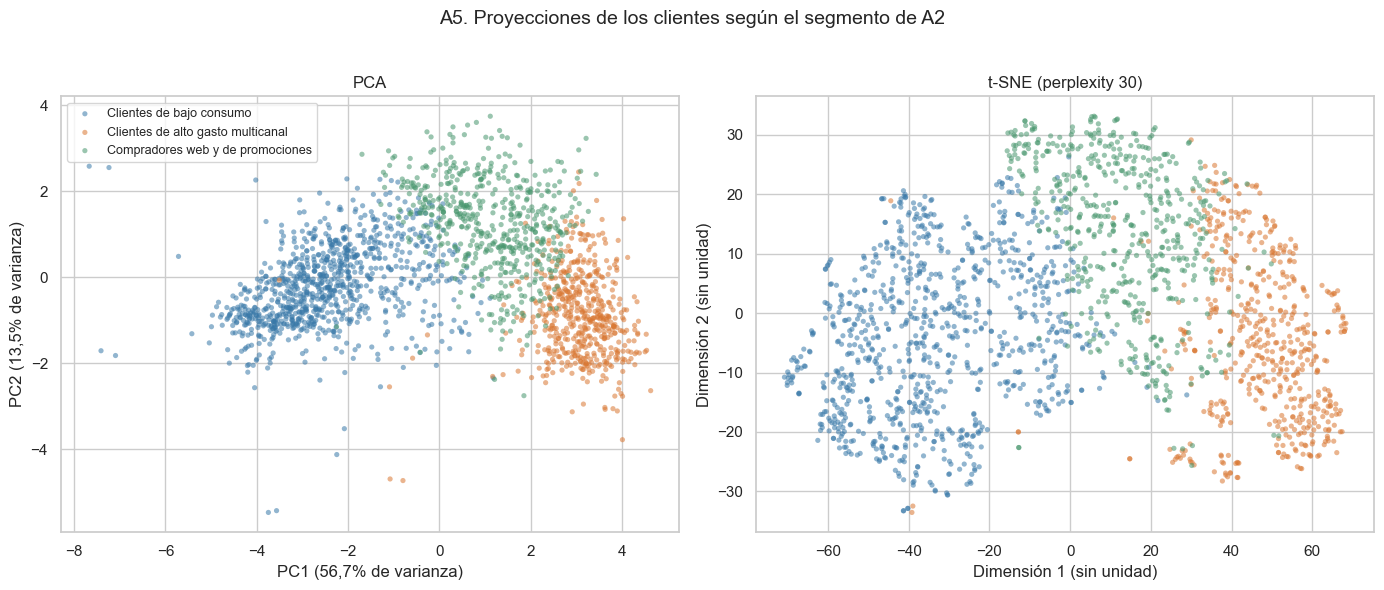

In [6]:
# Misma coloración para comparar: el segmento de A2
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for segmento, color in COLORES_SEGMENTOS.items():
    mascara = (df_unicos["Segmento"] == segmento).to_numpy()
    for ax, proyeccion in zip(axes, [X_pca, X_tsne]):
        ax.scatter(
            proyeccion[mascara, 0],
            proyeccion[mascara, 1],
            s=14,
            alpha=0.55,
            color=color,
            label=segmento,
            edgecolors="none"
        )

axes[0].set(
    title="PCA",
    xlabel=f"PC1 ({varianza_pca[0]:.1%} de varianza)".replace(".", ","),
    ylabel=f"PC2 ({varianza_pca[1]:.1%} de varianza)".replace(".", ",")
)
axes[1].set(
    title="t-SNE (perplexity 30)",
    xlabel="Dimensión 1 (sin unidad)",
    ylabel="Dimensión 2 (sin unidad)"
)
axes[0].legend(fontsize=9)

fig.suptitle("A5. Proyecciones de los clientes según el segmento de A2", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(ruta_figuras / "A5_01_tsne_vs_pca.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretación de las proyecciones

t-SNE conserva mejor los vecinos: su confianza es 0,9771 con `perplexity` 30,
frente a 0,8991 de PCA. El resultado casi no cambia entre 30 y 50 (0,9770), y baja
con 5 (0,9674), por lo que usamos 30.

PCA conserva el 70,18 % de la varianza en dos componentes y su eje principal se
puede interpretar: PC1 ordena a los clientes por intensidad de compra. Por eso
ambas técnicas se complementan: PCA explica la estructura general y t-SNE muestra
mejor quién está cerca de quién.

Ninguna de las dos proyecciones muestra grupos grandes separados por espacios
vacíos: los tres segmentos de A2 son zonas de un mismo continuo. Esto anticipa
que DBSCAN encontrará una masa principal, y no varios grupos de tamaño parecido.

**Precaución al leer t-SNE.** Las distancias entre manchas y su tamaño no tienen
significado directo, y sus agrupaciones visuales pueden ser efecto del algoritmo.
Por eso **DBSCAN no se aplica sobre t-SNE**, sino sobre las 12 variables
estandarizadas. t-SNE solo se usa para mostrar el resultado.

## 6. Detección de nichos con DBSCAN

DBSCAN agrupa los puntos que tienen al menos `min_samples` vecinos a una
distancia `eps` o menor, y marca como ruido a los que no pertenecen a ninguna
zona densa. A diferencia de k-means, no exige fijar el número de grupos ni
obliga a asignar a todos los clientes.

### 6.1 Curva de k-distancias

Para cada cliente medimos la distancia a su vecino número `min_samples`, y
ordenamos esas distancias. La curva sirve para acotar `eps`: por encima del codo
casi todos los clientes quedan unidos y ya no se puede aislar un grupo pequeño.

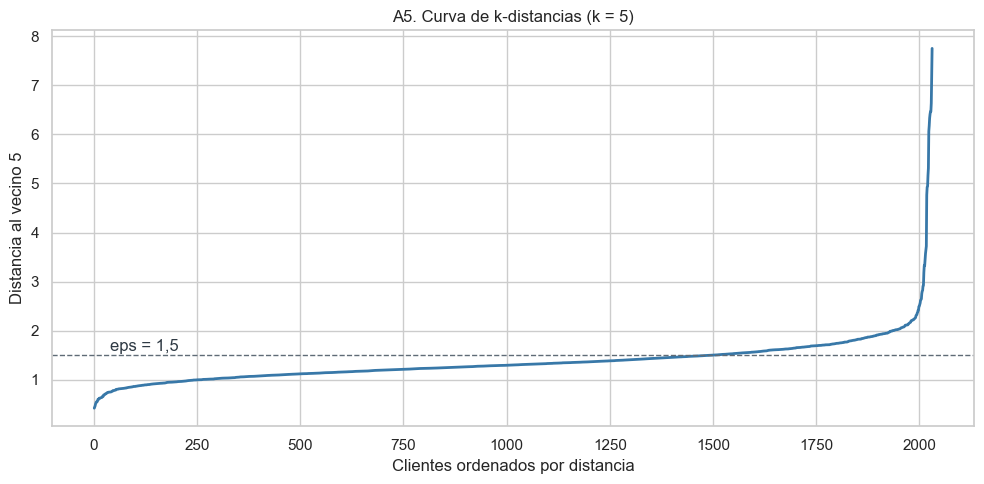

Percentiles de la distancia:
  P50: 1.31
  P75: 1.52
  P90: 1.79
  P95: 1.99
  P99: 3.11


In [7]:
MIN_SAMPLES_CURVA = 5

vecinos = NearestNeighbors(n_neighbors=MIN_SAMPLES_CURVA).fit(X_escalado)
distancias = np.sort(vecinos.kneighbors(X_escalado)[0][:, -1])

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(np.arange(1, len(distancias) + 1), distancias, color="#3878A8", linewidth=2)
ax.axhline(1.5, color=COLOR_RUIDO, linestyle="--", linewidth=1)
ax.annotate("eps = 1,5", xy=(40, 1.5), xytext=(40, 1.58), color="#2F3A44")
ax.set(
    title=f"A5. Curva de k-distancias (k = {MIN_SAMPLES_CURVA})",
    xlabel="Clientes ordenados por distancia",
    ylabel=f"Distancia al vecino {MIN_SAMPLES_CURVA}"
)
plt.tight_layout()
plt.savefig(ruta_figuras / "A5_02_curva_k_distancias.png", dpi=300, bbox_inches="tight")
plt.show()

print("Percentiles de la distancia:")
for p in [50, 75, 90, 95, 99]:
    print(f"  P{p}: {np.percentile(distancias, p):.2f}")

### 6.2 Búsqueda de parámetros

Probamos valores de `eps` por debajo del codo y los evaluamos con los criterios
de éxito. Se considera *grupo principal* al más grande y *nichos* a los
demás. La estabilidad es la de cada nicho al repetir DBSCAN con el 80 % de los
clientes, 30 veces, y medir el Jaccard con el grupo original más parecido.

In [9]:
def resumir_grupos(etiquetas):
    """Devuelve los tamaños de los grupos, de mayor a menor, sin el ruido."""
    return pd.Series(etiquetas[etiquetas >= 0]).value_counts()


def estabilidad_nicho(X, eps, min_samples, miembros, repeticiones=30):
    """Jaccard medio del nicho frente a DBSCAN sobre submuestras del 80 %.

    miembros contiene las posiciones (no los índices) de los clientes del nicho.
    Solo se comparan los miembros que entraron en cada submuestra.
    """
    n = len(X)
    resultados = []

    for repeticion in range(repeticiones):
        generador = np.random.RandomState(SEMILLA + repeticion)
        posiciones = generador.choice(n, int(0.8 * n), replace=False)
        etiquetas = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X[posiciones])

        presentes = set(posiciones) & set(miembros)
        mejor = 0.0

        for grupo in set(etiquetas) - {-1}:
            encontrados = set(posiciones[etiquetas == grupo])
            union = encontrados | presentes
            mejor = max(mejor, len(encontrados & presentes) / len(union))

        resultados.append(mejor)

    return float(np.mean(resultados))


X_matriz = X_escalado.to_numpy()
limite_nicho = 0.05 * len(X_matriz)
filas_busqueda = []

for min_samples in [5, 6, 8, 10, 14, 20]:
    for eps in np.round(np.arange(1.0, 2.31, 0.1), 1):
        etiquetas = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_matriz)
        tamanos = resumir_grupos(etiquetas)
        porcentaje_ruido = (etiquetas == -1).mean() * 100

        nichos = tamanos.iloc[1:]
        nichos = nichos[(nichos >= 10) & (nichos <= limite_nicho)]

        if nichos.empty:
            continue

        mejor_estabilidad = max(
            estabilidad_nicho(
                X_matriz, eps, min_samples, np.where(etiquetas == grupo)[0]
            )
            for grupo in nichos.index
        )

        filas_busqueda.append({
            "min_samples": min_samples,
            "eps": eps,
            "Grupos": len(tamanos),
            "Tamaños": tamanos.tolist(),
            "Ruido (%)": porcentaje_ruido,
            "Estabilidad del mejor nicho": mejor_estabilidad,
            "Cumple criterios": (
                porcentaje_ruido <= 20 and mejor_estabilidad >= 0.75
            )
        })

tabla_busqueda = pd.DataFrame(filas_busqueda)
display(tabla_busqueda.round(3))

,min_samples,eps,Grupos,Tamaños,Ruido (%),Estabilidad del mejor nicho,Cumple criterios
0,5,1.0,18,"[276, 63, 33, 11, 9, 6, 6, 6, 5, 5, 5, 5, 5, 5...",77.499,0.753,False
1,5,1.1,14,"[421, 183, 52, 30, 17, 13, 11, 6, 5, 5, 5, 5, ...",62.531,0.782,False
2,5,1.2,4,"[744, 338, 17, 5]",45.643,0.781,False
3,5,1.3,6,"[1353, 19, 7, 4, 3, 3]",31.610,0.833,False
4,5,1.5,2,"[1720, 17]",14.476,0.852,True
5,6,1.0,10,"[262, 38, 27, 19, 7, 6, 6, 6, 6, 5]",81.192,0.660,False
6,6,1.1,16,"[376, 167, 23, 23, 18, 15, 13, 9, 9, 7, 6, 6, ...",65.928,0.771,False
7,6,1.2,9,"[677, 246, 74, 15, 9, 5, 5, 5, 3]",48.843,0.749,False
8,6,1.3,4,"[1296, 17, 8, 5]",34.712,0.839,False
9,6,1.4,3,"[1545, 10, 7]",23.092,0.698,False


### Elección de parámetros

Sin un codo útil para decidir solo: la curva sube con fuerza por encima de 2, pero
allí todos los clientes forman un único grupo y no se aísla ningún nicho. Por eso
`eps` se decide con los criterios de éxito y la curva solo acota el rango.

De las 84 combinaciones probadas, solo dos cumplen los criterios, ambas con
`eps` = 1,5:

| `min_samples` | Tamaños | Ruido | Estabilidad |
|---|---|---|---|
| 5 | 1720 y 17 | 14,48 % | 0,85 |
| 6 | 1696 y 15 | 15,76 % | 0,80 |

La regla, aplicada en la siguiente celda, elige la más estable: `eps` = 1,5 y
`min_samples` = 5. Además deja menos ruido y contiene a los 15 clientes de la otra.

Revisar tantas combinaciones aumenta el riesgo de encontrar un grupo por azar. Por
eso el resultado se somete a las pruebas de la sección 6.3 y se contrasta con
variables que no intervinieron en el modelo.

In [10]:
# Regla: entre las combinaciones que cumplen, la de nicho más estable
fila_elegida = (
    tabla_busqueda[tabla_busqueda["Cumple criterios"]]
    .sort_values("Estabilidad del mejor nicho", ascending=False)
    .iloc[0]
)

EPS_ELEGIDO = float(fila_elegida["eps"])
MIN_SAMPLES_ELEGIDO = int(fila_elegida["min_samples"])
print(f"Parámetros elegidos: eps = {EPS_ELEGIDO}, min_samples = {MIN_SAMPLES_ELEGIDO}")

modelo_dbscan = DBSCAN(eps=EPS_ELEGIDO, min_samples=MIN_SAMPLES_ELEGIDO)
etiquetas_dbscan = modelo_dbscan.fit_predict(X_matriz)

tamanos_elegidos = resumir_grupos(etiquetas_dbscan)
grupo_principal = tamanos_elegidos.index[0]
grupos_nicho = tamanos_elegidos.index[1:].tolist()

NOMBRES_GRUPOS = {grupo_principal: "Masa principal", -1: "Casos aislados (ruido)"}
for numero, grupo in enumerate(grupos_nicho, start=1):
    NOMBRES_GRUPOS[grupo] = f"Nicho {numero}"

df_unicos["Grupo_DBSCAN"] = pd.Series(etiquetas_dbscan, index=df_unicos.index).map(NOMBRES_GRUPOS)

resumen_grupos = df_unicos["Grupo_DBSCAN"].value_counts().rename("Clientes").to_frame()
resumen_grupos["Porcentaje (%)"] = resumen_grupos["Clientes"] / len(df_unicos) * 100
display(resumen_grupos.round(2))

Parámetros elegidos: eps = 1.5, min_samples = 5


,Clientes,Porcentaje (%)
Grupo_DBSCAN,,
Masa principal,1720,84.69
Casos aislados (ruido),294,14.48
Nicho 1,17,0.84


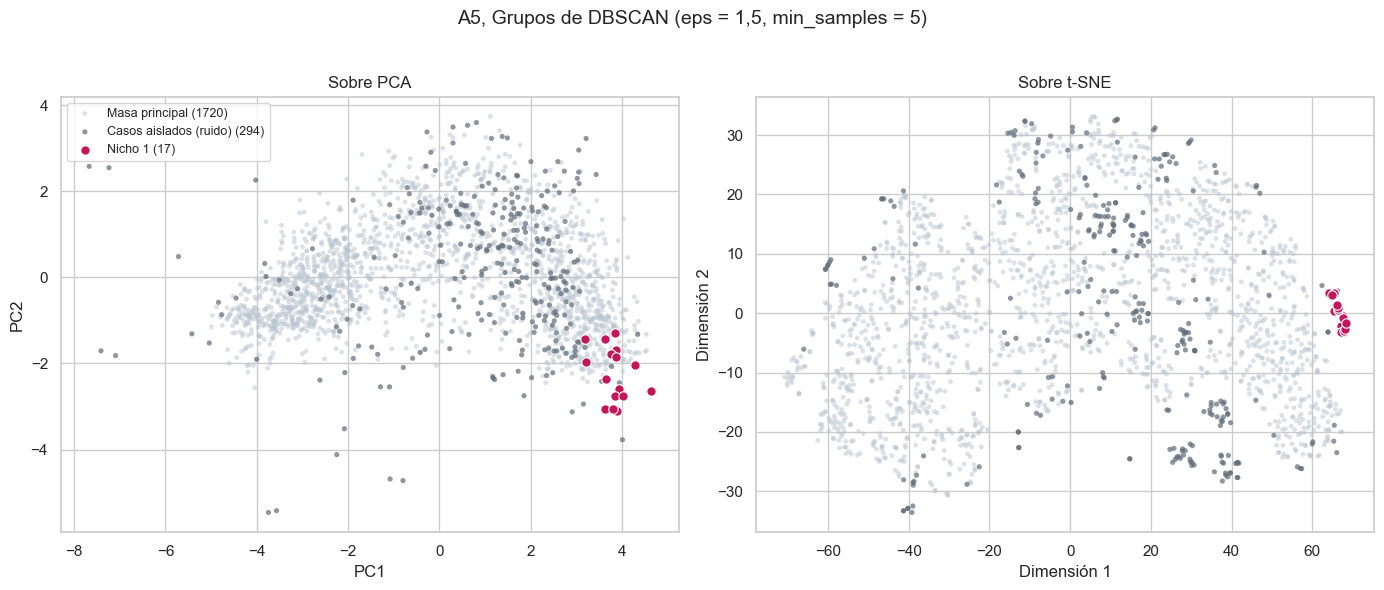

In [11]:
# Resultado de DBSCAN sobre las dos proyecciones
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

capas = [
    ("Masa principal", COLOR_MASA, 12, 0.5),
    ("Casos aislados (ruido)", COLOR_RUIDO, 14, 0.7),
]
capas += [(NOMBRES_GRUPOS[g], COLOR_NICHO, 46, 1.0) for g in grupos_nicho]

for ax, proyeccion in zip(axes, [X_pca, X_tsne]):
    for nombre, color, tamano, opacidad in capas:
        mascara = (df_unicos["Grupo_DBSCAN"] == nombre).to_numpy()
        ax.scatter(
            proyeccion[mascara, 0],
            proyeccion[mascara, 1],
            s=tamano,
            alpha=opacidad,
            color=color,
            label=f"{nombre} ({mascara.sum()})",
            edgecolors="white" if tamano > 20 else "none",
            linewidths=0.8
        )

axes[0].set(title="Sobre PCA", xlabel="PC1", ylabel="PC2")
axes[1].set(title="Sobre t-SNE", xlabel="Dimensión 1", ylabel="Dimensión 2")
axes[0].legend(fontsize=9)

fig.suptitle(
    f"A5. Grupos de DBSCAN (eps = {EPS_ELEGIDO}, min_samples = {MIN_SAMPLES_ELEGIDO})".replace(".", ","),
    fontsize=14
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(ruta_figuras / "A5_03_dbscan_proyecciones.png", dpi=300, bbox_inches="tight")
plt.show()

### 6.3 Estabilidad y sensibilidad del nicho

Un nicho solo sirve si reaparece. Hacemos tres pruebas:

- **Submuestras:** repetir DBSCAN con el 80 % de los clientes.
- **Parámetros vecinos:** mover `eps` y `min_samples` alrededor de lo elegido.
- **Duplicados:** repetir con los parámetros elegidos sobre los datos crudos, que
  aún tienen las copias, para medir cuánto habría cambiado el resultado.

In [12]:
def jaccard_con_nicho(etiquetas, miembros):
    """Mayor Jaccard entre algún grupo y los miembros del nicho."""
    mejor = 0.0
    miembros = set(miembros)
    for grupo in set(etiquetas) - {-1}:
        encontrados = set(np.where(etiquetas == grupo)[0])
        mejor = max(mejor, len(encontrados & miembros) / len(encontrados | miembros))
    return mejor


miembros_nicho = np.where(etiquetas_dbscan == grupos_nicho[0])[0]

estabilidad_final = estabilidad_nicho(
    X_matriz, EPS_ELEGIDO, MIN_SAMPLES_ELEGIDO, miembros_nicho
)
print(f"Jaccard medio en 30 submuestras del 80 %: {estabilidad_final:.2f}")

# Sensibilidad a los parámetros
filas_sensibilidad = []

for eps in [1.4, 1.5, 1.6, 1.7]:
    for min_samples in [5, 6, 7]:
        etiquetas = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_matriz)
        tamanos = resumir_grupos(etiquetas)
        filas_sensibilidad.append({
            "eps": eps,
            "min_samples": min_samples,
            "Tamaños": tamanos.tolist()[:5],
            "Ruido (%)": (etiquetas == -1).mean() * 100,
            "Jaccard con el nicho": jaccard_con_nicho(etiquetas, miembros_nicho)
        })

tabla_sensibilidad = pd.DataFrame(filas_sensibilidad)
display(tabla_sensibilidad.round(2))

# Efecto de conservar las filas duplicadas: se aplican los mismos filtros de
# 00_Datos.ipynb a los datos crudos, sin quitar las copias
df_crudo = pd.read_csv("data/raw/marketing_campaign.csv", sep="\t")
df_crudo["Income"] = df_crudo["Income"].fillna(df_crudo["Income"].median())
df_crudo = df_crudo[
    (2014 - df_crudo["Year_Birth"] <= 100) & (df_crudo["Income"] < 200000)
]

X_con_copias = StandardScaler().fit_transform(np.log1p(df_crudo[variables_densidad]))
etiquetas_copias = DBSCAN(
    eps=EPS_ELEGIDO, min_samples=MIN_SAMPLES_ELEGIDO
).fit_predict(X_con_copias)

print("\nCon filas duplicadas y los mismos parámetros:")
print(f"  Tamaños: {resumir_grupos(etiquetas_copias).tolist()}")
print(f"  Ruido: {(etiquetas_copias == -1).mean():.1%}")

Jaccard medio en 30 submuestras del 80 %: 0.85


,eps,min_samples,Tamaños,Ruido (%),Jaccard con el nicho
0,1.4,5,"[1581, 9, 8, 5, 5]",20.63,0.47
1,1.4,6,"[1545, 10, 7]",23.09,0.41
2,1.4,7,"[1504, 8]",25.55,0.00
3,1.5,5,"[1720, 17]",14.48,1.00
4,1.5,6,"[1696, 15]",15.76,0.88
5,1.5,7,"[1676, 12]",16.89,0.71
6,1.6,5,"[1812, 5, 5]",10.29,0.01
7,1.6,6,[1796],11.57,0.01
8,1.6,7,[1780],12.36,0.01
9,1.7,5,"[1862, 6, 6, 5, 4]",7.19,0.01



Con filas duplicadas y los mismos parámetros:
  Tamaños: [1893, 20, 5, 5]
  Ruido: 14.0%


### Lectura de las pruebas

- **Submuestras:** Jaccard medio de 0,85, superior a la meta de 0,75. El nicho
  reaparece aunque falte el 20 % de los clientes.
- **Parámetros vecinos:** es la prueba más débil. Se mantiene con `eps` = 1,5 y
  `min_samples` entre 5 y 7 (Jaccard de 1,00, 0,88 y 0,71), pero con `eps` = 1,6 se
  funde con la masa principal (Jaccard 0,01), y con `eps` = 1,4 se fragmenta (0,47).
  El nicho **no es una isla separada**, sino el borde de la zona de gasto alto.
- **Duplicados:** con las copias, el nicho pasa de 17 a 20 clientes y aparecen dos
  grupos de 5 que no existen en los registros únicos. Quitarlas evitó dos nichos
  falsos.

## 7. Perfil del nicho en unidades originales

Comparamos los grupos con promedios sin estandarizar. `Response` y las campañas
anteriores no se usaron para formarlos, así que funcionan como una comprobación
independiente.

Como los grupos son pequeños, acompañamos la tasa de respuesta con un intervalo
de Wilson al 95 %.

In [13]:
variables_perfil = [
    "Income",
    "Total_Spent",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
    "Total_Purchases",
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth",
    "Recency",
    "Age",
    "Children",
    "Family_Size",
    "Customer_Days",
    "Response",
    "AcceptedCmp1",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Complain"
]

orden_grupos = [NOMBRES_GRUPOS[g] for g in grupos_nicho]
orden_grupos += ["Masa principal", "Casos aislados (ruido)"]

perfil_grupos = (
    df_unicos.groupby("Grupo_DBSCAN")[variables_perfil].mean().loc[orden_grupos]
)
perfil_grupos.insert(0, "Clientes", df_unicos["Grupo_DBSCAN"].value_counts())
display(perfil_grupos.round(2).T)

print("\nSegmento de A2 de cada grupo de DBSCAN:")
display(pd.crosstab(df_unicos["Grupo_DBSCAN"], df_unicos["Segmento"]).loc[orden_grupos])

Grupo_DBSCAN,Nicho 1,Masa principal,Casos aislados (ruido)
Clientes,17.00,1720.00,294.00
Income,89558.29,50068.85,61521.59
Total_Spent,1692.29,538.46,941.23
MntWines,756.82,262.88,517.37
MntFruits,87.35,25.55,27.39
MntMeatProducts,569.53,148.85,255.71
MntFishProducts,94.06,35.67,44.47
MntSweetProducts,116.06,25.82,30.70
MntGoldProds,68.47,39.69,65.59
Total_Purchases,21.41,11.83,16.21



Segmento de A2 de cada grupo de DBSCAN:


Segmento,Clientes de alto gasto multicanal,Clientes de bajo consumo,Compradores web y de promociones
Grupo_DBSCAN,,,
Nicho 1,17,0,0
Masa principal,427,882,411
Casos aislados (ruido),100,56,138


### 7.1 ¿Qué define al nicho?

Revisamos si su separación se debe a una sola variable y comparamos su respuesta
con la de otros grupos, incluido el cuartil de mayor gasto que sí usa descuentos.

In [14]:
def intervalo_wilson(exitos, n, z=1.96):
    """Intervalo de confianza de Wilson al 95 % para una proporción."""
    p = exitos / n
    denominador = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / denominador
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominador
    return centro - margen, centro + margen


nombre_nicho = NOMBRES_GRUPOS[grupos_nicho[0]]
es_nicho = df_unicos["Grupo_DBSCAN"] == nombre_nicho
sin_descuento = df_unicos["NumDealsPurchases"] == 0
gasto_alto = df_unicos["Total_Spent"] >= df_unicos["Total_Spent"].quantile(0.75)

print(f"Clientes sin compras con descuento: {sin_descuento.sum()}")
print(
    "Grupo de esos clientes:",
    df_unicos.loc[sin_descuento, "Grupo_DBSCAN"].value_counts().to_dict()
)

grupos_comparados = {
    "Nicho (DBSCAN)": es_nicho,
    "Sin descuentos e ingreso >= 75 000": sin_descuento & (df_unicos["Income"] >= 75000),
    "Gasto alto (Q4) con descuentos": gasto_alto & ~sin_descuento,
    "Base de clientes únicos": pd.Series(True, index=df_unicos.index)
}

filas_respuesta = []

for nombre, mascara in grupos_comparados.items():
    n = int(mascara.sum())
    exitos = int(df_unicos.loc[mascara, "Response"].sum())
    inferior, superior = intervalo_wilson(exitos, n)
    filas_respuesta.append({
        "Grupo": nombre,
        "Clientes": n,
        "Gasto promedio": df_unicos.loc[mascara, "Total_Spent"].mean(),
        "Response (%)": exitos / n * 100,
        "IC 95 % inferior (%)": inferior * 100,
        "IC 95 % superior (%)": superior * 100
    })

tabla_respuesta = pd.DataFrame(filas_respuesta)
display(tabla_respuesta.round(1))

Clientes sin compras con descuento: 42
Grupo de esos clientes: {'Casos aislados (ruido)': 25, 'Nicho 1': 17}


,Grupo,Clientes,Gasto promedio,Response (%),IC 95 % inferior (%),IC 95 % superior (%)
0,Nicho (DBSCAN),17,1692.3,47.1,26.2,69.0
1,Sin descuentos e ingreso >= 75 000,32,1392.4,43.8,28.2,60.7
2,Gasto alto (Q4) con descuentos,482,1478.8,29.3,25.4,33.5
3,Base de clientes únicos,2031,606.4,14.9,13.4,16.5


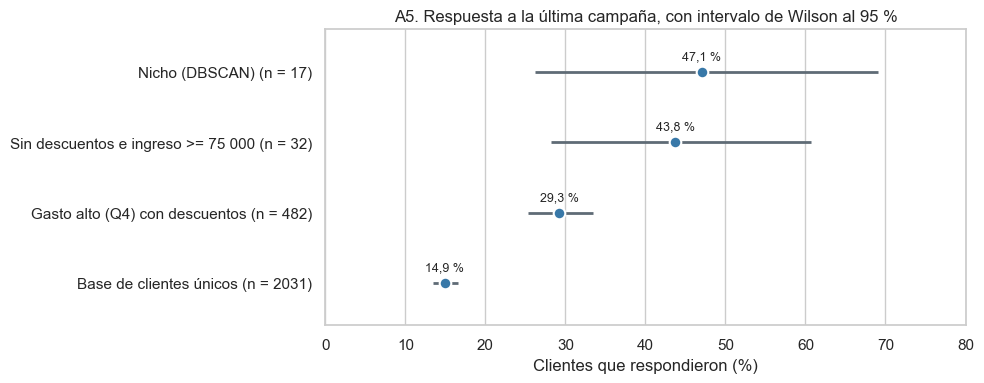

In [15]:
# Respuesta con su intervalo: un dato por grupo, misma escala
fig, ax = plt.subplots(figsize=(10, 4))
posiciones_y = np.arange(len(tabla_respuesta))[::-1]

ax.hlines(
    posiciones_y,
    tabla_respuesta["IC 95 % inferior (%)"],
    tabla_respuesta["IC 95 % superior (%)"],
    color=COLOR_RUIDO,
    linewidth=2
)
ax.scatter(
    tabla_respuesta["Response (%)"],
    posiciones_y,
    s=70,
    color="#3878A8",
    edgecolors="white",
    linewidths=1.5,
    zorder=3
)

for y, valor in zip(posiciones_y, tabla_respuesta["Response (%)"]):
    ax.annotate(f"{valor:.1f} %".replace(".", ","), (valor, y), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=9)

ax.set_yticks(
    posiciones_y,
    [f"{g} (n = {n})" for g, n in zip(tabla_respuesta["Grupo"], tabla_respuesta["Clientes"])]
)
ax.set(
    title="A5. Respuesta a la última campaña, con intervalo de Wilson al 95 %",
    xlabel="Clientes que respondieron (%)",
    xlim=(0, 80),
    ylim=(-0.6, len(tabla_respuesta) - 0.4)
)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(ruta_figuras / "A5_04_respuesta_nicho.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretación del nicho

**Nicho «Premium sin descuentos» (17 clientes, 0,84 % de los registros únicos).**

- Ingreso promedio de 89 558 frente a 50 069 de la masa principal.
- Gasto promedio de 1692 frente a 538, concentrado en vinos (757) y carnes (570).
- **Ninguno compró con descuento** y ninguno tiene hijos en casa.
- Pocas visitas web (1,94 al mes, frente a 5,41) pero 21,41 compras en promedio,
  principalmente en tienda (9,00) y catálogo (6,88).
- Todos pertenecen al segmento «Clientes de alto gasto multicanal» de A2: el nicho
  es un subgrupo que ese segmento no permite distinguir.

**Evidencia independiente.** El 47,1 % respondió a la última campaña (8 de 17),
frente al 14,9 % de la base, y aceptaron más las campañas 5 (65 % frente a 6 % de la
masa principal) y 1 (53 % frente a 5 %). Estas variables no intervinieron en el
modelo.

**Alcance de esa evidencia.**

- Frente a la base, la diferencia se sostiene: los intervalos no se solapan
  (26,2–69,0 % frente a 13,4–16,5 %).
- Frente a otros clientes de gasto alto **no es concluyente**: los intervalos se
  solapan (26,2–69,0 % frente a 25,4–33,5 %). Con 17 clientes no se puede afirmar
  que el nicho responda más que ellos.
- Es una asociación histórica. No demuestra que evitar descuentos cause la respuesta.

**Dependencia de una variable.** Los 42 clientes sin compras con descuento quedan
fuera de la masa principal: 17 en el nicho y 25 como casos aislados. Pasar de 0 a 1
compra es un salto grande en escala logarítmica, y eso contribuye a separar el
nicho. Por eso proponemos usar también una regla simple y más amplia: **sin compras
con descuento e ingreso de 75 000 o más** (32 clientes, 43,8 % de respuesta).

## 8. Casos aislados

El ruido de DBSCAN no significa error: es «no pertenece a una zona densa». Por eso
**no se eliminan estos clientes**. Separamos los que requieren una acción distinta
mediante reglas simples y verificables.

In [16]:
ruido = df_unicos[df_unicos["Grupo_DBSCAN"] == "Casos aislados (ruido)"]

categorias_aislados = {
    "Ingreso mayor a 120 000": ruido["Income"] > 120000,
    "Gasto registrado sin compras": (ruido["Total_Purchases"] == 0) & (ruido["Total_Spent"] > 0),
    "Sin descuentos (cerca del nicho)": ruido["NumDealsPurchases"] == 0,
    "10 o más compras con descuento": ruido["NumDealsPurchases"] >= 10
}

tabla_aislados = pd.DataFrame([
    {
        "Tipo de caso": nombre,
        "Clientes": int(mascara.sum()),
        "Ingreso promedio": ruido.loc[mascara, "Income"].mean(),
        "Gasto promedio": ruido.loc[mascara, "Total_Spent"].mean(),
        "Compras promedio": ruido.loc[mascara, "Total_Purchases"].mean()
    }
    for nombre, mascara in categorias_aislados.items()
])

display(tabla_aislados.round(1))

print(f"Total de casos aislados: {len(ruido)}")
print(f"Cubiertos por alguna regla: {pd.concat(categorias_aislados, axis=1).any(axis=1).sum()}")

,Tipo de caso,Clientes,Ingreso promedio,Gasto promedio,Compras promedio
0,Ingreso mayor a 120 000,7,158024.3,747.9,11.7
1,Gasto registrado sin compras,6,54160.7,7.0,0.0
2,Sin descuentos (cerca del nicho),25,78492.5,825.0,13.5
3,10 o más compras con descuento,16,59444.7,978.1,16.7


Total de casos aislados: 294
Cubiertos por alguna regla: 41


### Interpretación de los casos aislados

De los 294 casos aislados (14,48 %), 41 cumplen alguna regla; un cliente puede
cumplir más de una.

| Tipo de caso | Clientes | Acción propuesta |
|---|---|---|
| Ingreso mayor a 120 000 | 7 | Verificar el dato: su gasto promedio (748) es bajo para ese ingreso |
| Gasto registrado sin compras | 6 | Revisar el registro: tienen gasto pero ninguna compra por canal |
| Sin descuentos | 25 | Considerarlos en el piloto, si cumplen la regla de ingreso |
| 10 o más compras con descuento | 16 | Revisar la rentabilidad: gran uso de promociones |

Los otros 253 clientes solo están en zonas de baja densidad, y no se les propone
una acción particular. En t-SNE, varias islas pequeñas de clientes de gasto alto
aparecen como ruido, pero no forman un perfil común: muchos tienen alguna categoría
en cero. No se consideran nichos.

## 9. Puesta en práctica y monitoreo

### 9.1 Cómo se usaría

DBSCAN no asigna clientes nuevos: cada ejecución describe la base completa. Por
eso, en la operación diaria se usaría la **regla simple**: sin compras con descuento
e ingreso de 75 000 o más.

- **Analista de datos:** prepara cada mes la lista de clientes que cumplen la regla.
- **Jefe de Categorías:** diseña la oferta sin descuento, centrada en vinos y carnes.
- **Gerente de Marketing:** aprueba el piloto y evalúa sus resultados.

Se propone un piloto de ocho semanas, igual que en A2. Los clientes se asignan al
azar a tratamiento (reciben la oferta) o control (atención habitual), y ambos se
observan en el mismo período. Se necesita un identificador de cliente, porque la
base procesada no lo conserva.

Los casos que requieren revisión (ingresos extremos y gasto sin compras) pasan al
responsable de datos antes de usarse en cualquier campaña.

### 9.2 Cómo se monitorearía

| Indicador | Cálculo | Frecuencia | Alerta propuesta |
|---|---|---|---|
| Tamaño del grupo | Clientes que cumplen la regla | Mensual | Cambio mayor al 25 % |
| Efecto de la oferta | Respuesta del tratamiento − respuesta del control | Al terminar el piloto | Sin diferencia a favor |
| Compra con descuento | Clientes de la regla que empiezan a usar descuentos | Mensual | Más del 20 % |
| Contribución neta | (Ingresos − costos de campaña) / clientes del grupo | Al terminar el piloto | Valor negativo |
| Casos aislados | Porcentaje de ruido al repetir DBSCAN | Trimestral | Más del 20 % |

Estos umbrales son propuestas operativas, pendientes de validar. Cada trimestre se
repetirá DBSCAN para comprobar si el nicho sigue existiendo. Si los datos cambian,
primero se revisarán errores de carga y efectos de temporada, y `eps` se volverá a
elegir con el mismo procedimiento.

## 10. Exportación de resultados

Guardamos la asignación de cada registro único y las tablas de evaluación. La base
exportada conserva el índice de `data_limpia_original.csv` como referencia de fila;
no es un identificador comercial.

In [17]:
# Asignación por registro único
columnas_salida = variables_perfil + ["Segmento", "Grupo_DBSCAN"]
df_unicos[columnas_salida].to_csv(
    ruta_resultados / "A5_clientes_nichos.csv",
    index=True,
    index_label="Fila_base_limpia",
    encoding="utf-8-sig"
)

tablas = {
    "A5_comparacion_proyecciones.csv": tabla_proyecciones,
    "A5_busqueda_dbscan.csv": tabla_busqueda,
    "A5_sensibilidad_dbscan.csv": tabla_sensibilidad,
    "A5_respuesta_nicho.csv": tabla_respuesta,
    "A5_casos_aislados.csv": tabla_aislados
}

for nombre, tabla in tablas.items():
    tabla.to_csv(ruta_tablas / nombre, index=False, encoding="utf-8-sig")

perfil_grupos.to_csv(
    ruta_tablas / "A5_perfiles_grupos.csv", index=True, encoding="utf-8-sig"
)

print("Archivos guardados correctamente.")

Archivos guardados correctamente.


## 11. Conclusiones del área A5

Se analizaron 2031 registros únicos con 12 variables de ingresos y compra. Las
filas repetidas se excluyeron porque habrían fabricado densidad artificial: 204 en
`00_Datos.ipynb` y una más aquí.

t-SNE conservó mejor los vecinos que PCA (confianza de 0,9771 frente a 0,8991).
Ambas proyecciones muestran un continuo, sin grupos grandes bien separados.

DBSCAN (`eps` = 1,5, `min_samples` = 5) encontró una masa principal de 1720
clientes, un nicho de 17 y 294 casos aislados.

| Criterio | Meta | Resultado | Estado |
|---|---|---|---|
| Tamaño del nicho | 10 clientes o más, hasta 5 % | 17 clientes (0,84 %) | Cumple |
| Estabilidad | Jaccard de 0,75 o más | 0,85 | Cumple |
| Ruido | Hasta 20 % | 14,48 % | Cumple |
| Perfil interpretable | Unidades originales | «Premium sin descuentos» | Cumple |

**Respuesta a la pregunta de negocio.** Sí existe un grupo pequeño que la
segmentación general no muestra: clientes de ingreso y gasto altos que nunca
compran con descuento. El resultado es exploratorio, porque el nicho depende de
`eps` y es demasiado pequeño para sostener una decisión por sí solo.

**Recomendación.** Probar en un piloto, sobre los 32 clientes de la regla amplia,
una oferta sin descuento (acceso anticipado o selección de vinos y carnes por
catálogo y tienda), comparada con un grupo de control. Con ese tamaño, el piloto
solo puede orientar; para sacar conclusiones habría que repetirlo con más clientes.
El error más costoso sería ofrecerles descuentos innecesarios o saturarlos.

**Limitaciones.**

- Los datos son simulados: el nicho ilustra el método y no describe clientes reales.
- El nicho desaparece con `eps` = 1,6 y se fragmenta con 1,4.
- La escala logarítmica amplía la distancia entre 0 y 1 en las variables de conteo.
- El grupo de 17 clientes da intervalos amplios para la tasa de respuesta.
- La base no conserva un ID de cliente, por lo que los resultados no se pueden
  vincular a personas concretas sin una etapa adicional.
- Aunque las filas repetidas se trataron como copias, podrían ser clientes reales
  distintos; la base no permite confirmarlo porque el ID no se conservó.

## 12. Entorno de ejecución

Registramos las versiones usadas. Son las mismas que en `reports/A2_entorno.txt`.

In [18]:
import platform
from importlib.metadata import version

paquetes_a5 = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "scipy",
    "ipython",
    "ipykernel"
]

lineas_entorno = [f"Python: {platform.python_version()}", "", "Librerías:"]
lineas_entorno.extend(f"{p}=={version(p)}" for p in paquetes_a5)
texto_entorno = "\n".join(lineas_entorno)

ruta_entorno = Path("reports/A5_entorno.txt")
ruta_entorno.write_text(texto_entorno, encoding="utf-8")

print(texto_entorno)

Python: 3.13.7

Librerías:
numpy==2.2.6
pandas==3.0.0
matplotlib==3.10.8
seaborn==0.13.2
scikit-learn==1.9.1
scipy==1.18.1
ipython==9.17.1
ipykernel==7.4.0
